# 04 First order conduit stats

In [1]:
import numpy as np

import matplotlib.pyplot as plt
import numpy as np

from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm

import base.geometry as geom

from base.utils import list_all_centrelines, return_centreline_parametrisation

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
centreline_filepaths = list_all_centrelines(data_repository)

In [3]:
idx = 6
sections_directory = join(split(centreline_filepaths[idx])[0], "sections")

In [6]:
centreline = np.loadtxt(centreline_filepaths[idx], skiprows=1)
curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline)

In [7]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

In [20]:
fill_curves = np.array([np.loadtxt(join(sections_directory, f"fill_curve_s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))])

In [28]:
dhi = 4*fill_curves[:, 1:-1, 1] / fill_curves[:, 1:-1, 2]

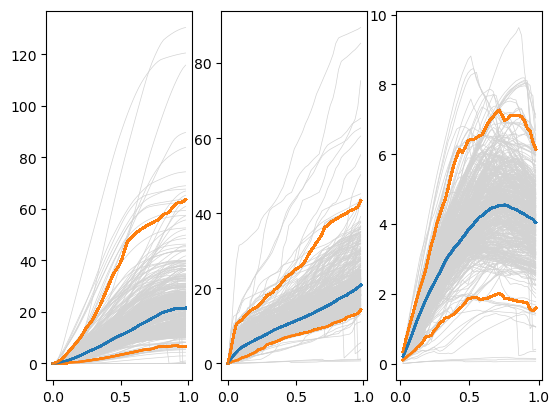

In [35]:
fig, axes = plt.subplots(1, 3)

for fill_curve in fill_curves:
    dh = 4*fill_curve[1:-1, 1] / fill_curve[1:-1, 2]

    axes[0].plot(*fill_curve[:-1, [0, 1]].T, color = "lightgrey", lw = 0.5)
    axes[1].plot(*fill_curve[:-1, [0, 2]].T, color = "lightgrey", lw = 0.5)
    axes[2].plot(fill_curve[1:-1, 0], dh, color = "lightgrey", lw = 0.5)
    
    for q, color in zip((0.025, 0.5, 0.975), ("C1", "C0", "C1")):
        axes[0].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 1],q,  axis =0), color = color)
        axes[1].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 2],q,  axis =0), color = color)
        axes[2].plot(fill_curve[1:-1, 0], np.quantile(dhi, q, axis = 0), color = color)
plt.show()